# Stock Risk Report

This notebook generates a parameterized risk report for an individual stock using the cleaned OHLC dataset.

The report loads observations for a specified ticker and date range, calculates adjusted-close log returns and risk metrics, generates visualizations, and presents a summary table.

The notebook is designed to run interactively or through Papermill as part of an automated reporting pipeline.

In [1]:
# Parameters for the stock risk report
ticker = "AAPL"
start_date = "2024-06-01"
end_date = "2024-11-30"

rolling_window = 21
risk_free_rate = 0.0

In [2]:
# Parameters
ticker = "MRK"
start_date = "2024-06-01"
end_date = "2024-11-30"
rolling_window = 21
risk_free_rate = 0.0


## Load clean stock data

In [3]:
from pathlib import Path
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_database():
    """Find the project database without hard-coding an absolute path."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidate = base / "course_file_export" / "data.db"
        if candidate.is_file():
            return candidate.resolve()

    raise FileNotFoundError(
        "Could not find course_file_export/data.db. "
        "Run this notebook from within the project repository."
    )


DB_PATH = find_database()

query = """
SELECT ts, ticker, open, high, low, close, adj_close, volume
FROM ohlc_hw_cleaned
WHERE ticker = ?
  AND ts >= ?
  AND ts <= ?
ORDER BY ts
"""

with sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True) as conn:
    stock_df = pd.read_sql_query(
        query,
        conn,
        params=(ticker, start_date, end_date),
    )

stock_df["ts"] = pd.to_datetime(stock_df["ts"])

if stock_df.empty:
    raise ValueError(
        f"No observations found for {ticker} "
        f"between {start_date} and {end_date}."
    )

if stock_df["ts"].duplicated().any():
    raise ValueError(
        f"Duplicate dates found for ticker {ticker}."
    )

print(f"Ticker: {ticker}")
print(f"Observations: {len(stock_df):,}")
print(f"Actual date range: {stock_df['ts'].min().date()} "
      f"to {stock_df['ts'].max().date()}")

display(stock_df.head())
display(stock_df.tail())

Ticker: MRK
Observations: 126
Actual date range: 2024-06-03 to 2024-11-29


,ts,ticker,open,high,low,close,adj_close,volume
0,2024-06-03,MRK,125.77,128.95,125.77,128.42,126.81,7702676
1,2024-06-04,MRK,127.15,129.36,126.88,128.71,127.09,6440167
2,2024-06-05,MRK,128.48,129.94,128.07,129.45,127.82,5009502
3,2024-06-06,MRK,129.16,130.93,128.90,130.52,128.88,8088641
4,2024-06-07,MRK,130.35,131.37,130.21,130.67,129.03,4945600


,ts,ticker,open,high,low,close,adj_close,volume
121,2024-11-22,MRK,100.33,101.79,98.93,99.18,99.18,14031200
122,2024-11-25,MRK,100.09,101.74,99.51,101.16,101.16,34659100
123,2024-11-26,MRK,101.48,101.80,99.70,101.62,101.62,9324100
124,2024-11-27,MRK,101.65,103.45,101.64,103.12,103.12,9802200
125,2024-11-29,MRK,102.88,103.04,101.53,101.64,101.64,6081200


## Return Calculation and Risk Metrics

Daily log returns are calculated using adjusted closing prices to account for the effects of corporate actions reflected in the adjusted price series.

The report calculates annualized volatility, the annualized Sharpe ratio, maximum drawdown, and cumulative return. Metrics are calculated from the observations within the selected date range. Annualized metrics use 252 trading days per year.

The Sharpe ratio uses the configured annual risk-free rate, converted to a daily rate for comparison with daily log returns. Maximum drawdown measures the largest decline from a running peak in the adjusted-price wealth index.

In [4]:
TRADING_DAYS_PER_YEAR = 252


def calculate_log_returns(prices):
    """Calculate daily log returns from a positive price series."""
    prices = pd.to_numeric(prices, errors="coerce")

    if (prices.dropna() <= 0).any():
        raise ValueError("Prices must be positive to calculate log returns.")

    return np.log(prices / prices.shift(1))


def annualized_volatility(log_returns):
    """Calculate annualized sample volatility from daily log returns."""
    returns = log_returns.dropna()

    if len(returns) < 2:
        return np.nan

    return returns.std(ddof=1) * np.sqrt(TRADING_DAYS_PER_YEAR)


def annualized_sharpe_ratio(log_returns, annual_risk_free_rate=0.0):
    """Calculate annualized Sharpe ratio using daily log returns."""
    returns = log_returns.dropna()

    if len(returns) < 2:
        return np.nan

    daily_rf = np.log1p(annual_risk_free_rate) / TRADING_DAYS_PER_YEAR
    excess_returns = returns - daily_rf
    daily_volatility = excess_returns.std(ddof=1)

    if not np.isfinite(daily_volatility) or daily_volatility == 0:
        return np.nan

    return (
        excess_returns.mean()
        / daily_volatility
        * np.sqrt(TRADING_DAYS_PER_YEAR)
    )


def maximum_drawdown(prices):
    """Calculate the maximum peak-to-trough drawdown of a price series."""
    prices = pd.to_numeric(prices, errors="coerce").dropna()

    if prices.empty:
        return np.nan

    running_peak = prices.cummax()
    drawdowns = prices / running_peak - 1

    return drawdowns.min()


def cumulative_return(prices):
    """Calculate total simple return over the selected price series."""
    prices = pd.to_numeric(prices, errors="coerce").dropna()

    if len(prices) < 2 or prices.iloc[0] <= 0:
        return np.nan

    return prices.iloc[-1] / prices.iloc[0] - 1

In [5]:
# Sort data chronologically before calculating returns.
stock_df = stock_df.sort_values("ts").reset_index(drop=True)

stock_df["log_return"] = calculate_log_returns(
    stock_df["adj_close"]
)

stock_df["simple_return"] = stock_df["adj_close"].pct_change(
    fill_method=None
)

metrics = {
    "Ticker": ticker,
    "Start date": stock_df["ts"].min().date(),
    "End date": stock_df["ts"].max().date(),
    "Observations": len(stock_df),
    "Cumulative return": cumulative_return(stock_df["adj_close"]),
    "Annualized volatility": annualized_volatility(stock_df["log_return"]),
    "Annualized Sharpe ratio": annualized_sharpe_ratio(
        stock_df["log_return"],
        risk_free_rate,
    ),
    "Maximum drawdown": maximum_drawdown(stock_df["adj_close"]),
}

metrics_df = pd.DataFrame(
    [{"Metric": key, "Value": value} for key, value in metrics.items()]
)

display(metrics_df)

,Metric,Value
0,Ticker,MRK
1,Start date,2024-06-03
2,End date,2024-11-29
3,Observations,126
4,Cumulative return,-0.198486
5,Annualized volatility,0.240922
6,Annualized Sharpe ratio,-1.85141
7,Maximum drawdown,-0.270821


In [6]:
print("Remaining extreme adjusted-close values:")
print(
    stock_df.loc[
        (stock_df["adj_close"] > stock_df["close"] * 1.1)
        | (stock_df["adj_close"] < stock_df["close"] * 0.9),
        ["ts", "close", "adj_close"]
    ]
)

Remaining extreme adjusted-close values:
Empty DataFrame
Columns: [ts, close, adj_close]
Index: []


### Risk Dashboard

This dashboard visualizes adjusted closing prices, daily log returns, rolling annualized volatility, and drawdowns. Rolling volatility uses a configurable window of trading observations, while drawdown measures the percentage decline from the running peak. These plots complement the summary metrics by showing how risk and performance evolve over time.

In [7]:
# Calculate rolling annualized volatility
stock_df["rolling_volatility"] = (
    stock_df["log_return"]
    .rolling(
        window=rolling_window,
        min_periods=rolling_window
    )
    .std(ddof=1)
    * np.sqrt(TRADING_DAYS_PER_YEAR)
)

# Calculate drawdown from the running peak
stock_df["running_peak"] = stock_df["adj_close"].cummax()

stock_df["drawdown"] = (
    stock_df["adj_close"] / stock_df["running_peak"] - 1
)

# Check the calculated values
display(
    stock_df[
        ["ts", "adj_close", "rolling_volatility", "drawdown"]
    ].tail(10)
)

,ts,adj_close,rolling_volatility,drawdown
116,2024-11-15,96.31,0.182609,-0.270821
117,2024-11-18,96.56,0.184635,-0.268928
118,2024-11-19,96.54,0.175574,-0.269079
119,2024-11-20,97.44,0.180377,-0.262265
120,2024-11-21,99.86,0.206222,-0.243943
121,2024-11-22,99.18,0.206573,-0.249091
122,2024-11-25,101.16,0.213482,-0.234101
123,2024-11-26,101.62,0.214077,-0.230618
124,2024-11-27,103.12,0.220473,-0.219261
125,2024-11-29,101.64,0.222007,-0.230466


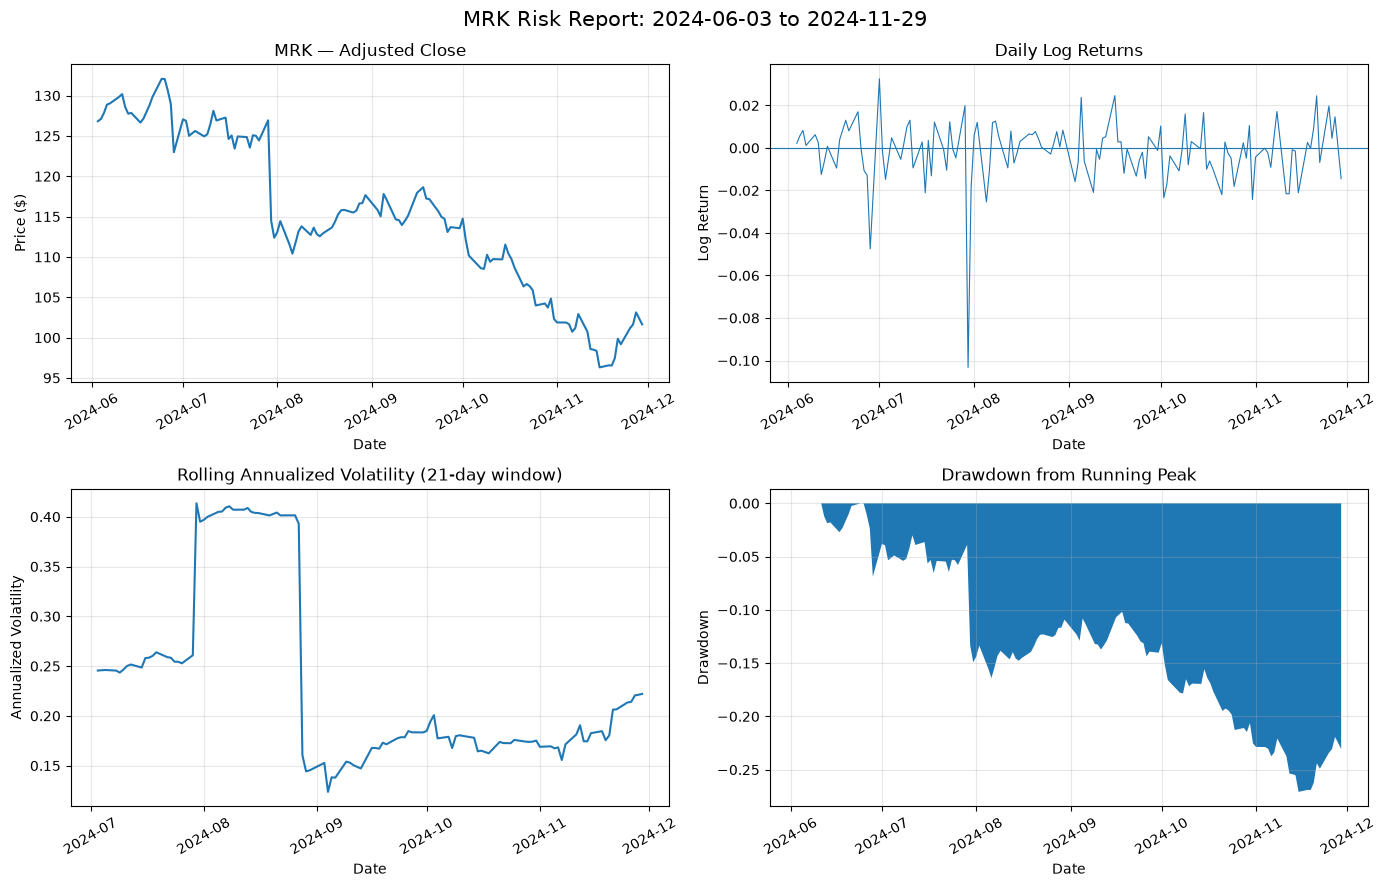

In [8]:
# Create a 2x2 risk dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Adjusted closing price
axes[0, 0].plot(stock_df["ts"], stock_df["adj_close"])
axes[0, 0].set_title(f"{ticker} — Adjusted Close")
axes[0, 0].set_ylabel("Price ($)")

# 2. Daily log returns
axes[0, 1].plot(
    stock_df["ts"], stock_df["log_return"], linewidth=0.8
)
axes[0, 1].axhline(0, linewidth=0.8)
axes[0, 1].set_title("Daily Log Returns")
axes[0, 1].set_ylabel("Log Return")

# 3. Rolling annualized volatility
axes[1, 0].plot(
    stock_df["ts"], stock_df["rolling_volatility"]
)
axes[1, 0].set_title(
    f"Rolling Annualized Volatility ({rolling_window}-day window)"
)
axes[1, 0].set_ylabel("Annualized Volatility")

# 4. Drawdown from running peak
axes[1, 1].fill_between(
    stock_df["ts"], stock_df["drawdown"], 0
)
axes[1, 1].set_title("Drawdown from Running Peak")
axes[1, 1].set_ylabel("Drawdown")

# Format all panels
for ax in axes.flat:
    ax.set_xlabel("Date")
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=30)

fig.suptitle(
    f"{ticker} Risk Report: {stock_df['ts'].min().date()} "
    f"to {stock_df['ts'].max().date()}",
    fontsize=15,
)
fig.tight_layout()
plt.show()

### Validation and Quality Checks

The report validates the selected stock's data before producing the final outputs. It checks for missing or non-finite prices, duplicate dates, invalid adjusted-close values, and non-finite calculated metrics. The report also distinguishes the requested analysis period from the actual dates available in the dataset.

In [9]:
# Validate the report data and calculated metrics

assert not stock_df.empty, "No stock observations were loaded."
assert stock_df["ts"].is_monotonic_increasing, "Dates are not sorted."
assert not stock_df["ts"].duplicated().any(), "Duplicate dates found."

assert stock_df["adj_close"].notna().all(), "Missing adjusted-close values."
assert np.isfinite(stock_df["adj_close"]).all(), "Non-finite adjusted-close values."
assert (stock_df["adj_close"] > 0).all(), "Non-positive adjusted-close values."

assert stock_df["log_return"].iloc[1:].notna().all(), (
    "Missing log returns after the first observation."
)
assert np.isfinite(stock_df["log_return"].iloc[1:]).all(), (
    "Non-finite log returns found."
)

assert np.isfinite(metrics["Cumulative return"]), "Invalid cumulative return."
assert np.isfinite(metrics["Annualized volatility"]), "Invalid annualized volatility."
assert np.isfinite(metrics["Maximum drawdown"]), "Invalid maximum drawdown."

print("All stock report validation checks passed!")
print(f"Ticker: {ticker}")
print(f"Requested period: {start_date} to {end_date}")
print(
    f"Actual data coverage: {stock_df['ts'].min().date()} "
    f"to {stock_df['ts'].max().date()}"
)
print(f"Observations: {len(stock_df)}")

All stock report validation checks passed!
Ticker: MRK
Requested period: 2024-06-01 to 2024-11-30
Actual data coverage: 2024-06-03 to 2024-11-29
Observations: 126


### Save Report Outputs

Save the stock's summary metrics and daily analysis data as CSV files. The output directory is organized by ticker so that reports can be generated consistently for multiple stocks. The report records both the requested analysis period and the actual available data coverage.

In [10]:

from pathlib import Path

# Find the repository root, even if the notebook is run
# from a different working directory.
current_path = Path.cwd().resolve()
project_root = next(
    (
        path
        for path in [current_path, *current_path.parents]
        if (path / "course_file_export" / "data.db").exists()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the repository root containing "
        "course_file_export/data.db"
    )

homework_dir = (
    project_root / "Homeworks" / "HW2" / "Vanditha_Toleti"
)

report_dir = homework_dir / "reports" / ticker
report_dir.mkdir(parents=True, exist_ok=True)

metrics_df.to_csv(report_dir / "metrics.csv", index=False)
stock_df.to_csv(report_dir / "daily_analysis.csv", index=False)

print(f"Reports saved to: {report_dir}")


Reports saved to: /Users/vandu/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Vanditha_Toleti/reports/MRK
